<!-- d2l:prose id=fm-md-1 fw=all -->

# Factorization Machines

A linear model assigns a separate weight to every feature but cannot change the contribution of one feature according to another. Explicitly assigning a parameter to every feature pair is usually infeasible for sparse, high-dimensional inputs. A second-order factorization machine (FM) [@Rendle.2010] gives each feature a $k$-dimensional vector and uses vector inner products as pairwise coefficients. This low-rank parameterization shares statistical strength across pairs and admits a computation linear in the number of active features.


## 2-Way Factorization Machines

For an input $\mathbf{x}\in\mathbb{R}^d$, a second-order FM has score

$$
\hat{y}(\mathbf{x}) = w_0 + \sum_{i=1}^d w_i x_i + \sum_{i=1}^d\sum_{j=i+1}^d \langle\mathbf{v}_i, \mathbf{v}_j\rangle x_i x_j.
$$

Here $w_0\in\mathbb{R}$ is an intercept, $\mathbf{w}\in\mathbb{R}^d$ contains the linear coefficients, and the rows $\mathbf{v}_i\in\mathbb{R}^k$ of $\mathbf{V}\in\mathbb{R}^{d\times k}$ determine the pairwise coefficients. The coefficient for $x_ix_j$ is not free: it must equal $\langle\mathbf{v}_i,\mathbf{v}_j\rangle$. For one-hot user and item features, this pairwise term contains the matrix-factorization score as a special case. Higher-order FMs require additional parameterizations; they do not follow from the second-order equation merely by increasing $k$.


## An Efficient Optimization Criterion

Directly summing all feature pairs costs $O(kd^2)$ for a dense input. For latent coordinate $l$, expand $(\sum_i v_{i,l}x_i)^2$: its cross terms count every unordered pair twice, while $\sum_i v_{i,l}^2x_i^2$ contains the diagonal terms. Subtracting the diagonal and dividing by two gives

$$
\begin{aligned}
&\sum_{i=1}^d \sum_{j=i+1}^d \langle\mathbf{v}_i, \mathbf{v}_j\rangle x_i x_j \\
 &= \frac{1}{2} \sum_{i=1}^d \sum_{j=1}^d\langle\mathbf{v}_i, \mathbf{v}_j\rangle x_i x_j - \frac{1}{2}\sum_{i=1}^d \langle\mathbf{v}_i, \mathbf{v}_i\rangle x_i x_i \\
 &= \frac{1}{2} \big (\sum_{i=1}^d \sum_{j=1}^d \sum_{l=1}^k\mathbf{v}_{i, l} \mathbf{v}_{j, l} x_i x_j - \sum_{i=1}^d \sum_{l=1}^k \mathbf{v}_{i, l} \mathbf{v}_{i, l} x_i x_i \big)\\
 &=  \frac{1}{2} \sum_{l=1}^k \big ((\sum_{i=1}^d \mathbf{v}_{i, l} x_i) (\sum_{j=1}^d \mathbf{v}_{j, l}x_j) - \sum_{i=1}^d \mathbf{v}_{i, l}^2 x_i^2 \big ) \\
 &= \frac{1}{2} \sum_{l=1}^k \big ((\sum_{i=1}^d \mathbf{v}_{i, l} x_i)^2 - \sum_{i=1}^d \mathbf{v}_{i, l}^2 x_i^2 \big )
 \end{aligned}
$$

The two inner sums can be accumulated in one pass. The cost is therefore $O(kd)$ for a dense vector and $O(k\,\mathrm{nnz}(\mathbf{x}))$ when only nonzero entries are visited.

To learn the FM model, we can use the MSE loss for regression task, the cross-entropy loss for classification tasks, and the BPR loss for ranking task. Standard optimizers such as stochastic gradient descent and Adam are viable for optimization.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import os

<!-- d2l:prose id=fm-md-2 fw=all -->

## Model Implementation
The implementation computes the linear term and the square-of-sum identity separately. It returns logits; a loss that combines the sigmoid and binary cross-entropy avoids explicitly taking logarithms of probabilities near zero or one.

<!-- d2l:prose id=fm-md-3 fw=pytorch -->

In PyTorch this loss is `BCEWithLogitsLoss`.

In [3]:
class FM(nn.Module):
    def __init__(self, field_dims, num_factors):
        super().__init__()
        num_inputs = int(sum(field_dims))
        self.embedding = nn.Embedding(num_inputs, num_factors)
        self.fc = nn.Embedding(num_inputs, 1)
        self.linear_layer = nn.Linear(1, 1)

    def forward(self, x):
        square_of_sum = self.embedding(x).sum(dim=1) ** 2
        sum_of_square = (self.embedding(x) ** 2).sum(dim=1)
        x = self.linear_layer(self.fc(x).sum(dim=1)) \
            + 0.5 * (square_of_sum - sum_of_square).sum(dim=1, keepdim=True)
        return x

<!-- d2l:prose id=fm-md-4 fw=all -->

## Load the Advertising Dataset
We use the CTR data wrapper from the last section to load the online advertising dataset.

In [4]:
batch_size = 2048
data_dir = d2l.download_extract('ctr')
train_data = d2l.CTRDataset(os.path.join(data_dir, 'train.csv'))
test_data = d2l.CTRDataset(os.path.join(data_dir, 'test.csv'),
                           feat_mapper=train_data.feat_mapper,
                           defaults=train_data.defaults)
train_iter = torch.utils.data.DataLoader(
    train_data, shuffle=True, drop_last=True, batch_size=batch_size,
    num_workers=d2l.get_dataloader_workers())
test_iter = torch.utils.data.DataLoader(
    test_data, shuffle=False, drop_last=True, batch_size=batch_size,
    num_workers=d2l.get_dataloader_workers())

<!-- d2l:prose id=fm-md-5 fw=all -->

## Train the Model
Afterwards, we train the model. The learning rate is set to 0.02 and the embedding size is set to 20 by default. The `Adam` optimizer and the loss that combines the sigmoid and binary cross-entropy are used for model training.

loss 0.006, train acc 1.000, test acc 0.932
192108.8 examples/sec on [device(type='cuda', index=0)]


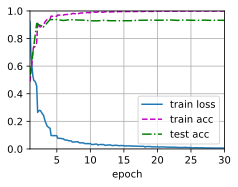

In [5]:
devices = d2l.try_all_gpus()
net = FM(train_data.field_dims, num_factors=20)

def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.xavier_uniform_(m.weight)
    if type(m) == nn.Embedding:
        nn.init.xavier_uniform_(m.weight)

net.apply(init_weights)
lr, num_epochs = 0.02, 30
optimizer = torch.optim.Adam(net.parameters(), lr=lr)
loss = nn.BCEWithLogitsLoss(reduction='none')
d2l.train_ch13(net, train_iter, test_iter, loss, optimizer, num_epochs, devices)

<!-- d2l:prose id=fm-md-6 fw=all -->

## Summary

* A second-order FM parameterizes every pair coefficient as an inner product of feature vectors, sharing parameters across sparse feature pairs.
* Its pairwise score costs $O(k\,\mathrm{nnz}(\mathbf{x}))$ using the square-of-sum identity.

## Exercises

1. For an input with a one-hot user field and a one-hot item field, show that
   the FM score is $w_0+w_u+w_i+\langle\mathbf v_u,\mathbf v_i\rangle$, matrix
   factorization with biases and a global offset. Add a third one-hot field
   for the hour of the day, write out the pairwise terms, and count the
   parameters of the FM with $k=20$ for field sizes 943, 1,682, and 24. Compare
   with a model that has a free weight for every pair of features from
   different fields.
1. Show that the derivative of the pairwise term with respect to $v_{i,l}$ is
   $x_i\sum_j v_{j,l}x_j-v_{i,l}x_i^2$. Explain how the sums computed in the
   forward pass give the gradient for all $k\,\mathrm{nnz}(\mathbf x)$ active
   embedding coordinates in $O(k\,\mathrm{nnz}(\mathbf x))$ time.
1. `train_ch13` reports accuracy only. Record the training and test log loss
   after every epoch and find the epoch at which the test log loss is lowest.
   Then train with $k\in\{2, 8, 20\}$ and a model without the pairwise term,
   which is logistic regression on the same features, and report the lowest
   test log loss of each. How much does the pairwise term improve on logistic
   regression on this dataset?
1. Encode MovieLens 100K as two fields, user and item, with the offset scheme
   of `CTRDataset`, train `FM` with the squared loss on the `seq-aware` split,
   and compare its test RMSE with that of `MF` on the same split. Use the
   first problem to explain why the two values should be close. Which
   additional field derived from the MovieLens data could make them differ?
1. Show that no second-order FM, for any $k$, represents the three-way
   interaction $x_1x_2x_3$ of three binary features exactly on all eight
   inputs. A third-order term
   $\sum_{i<j<l}\sum_{f=1}^k v_{i,f}v_{j,f}v_{l,f}\,x_ix_jx_l$ fixes this.
   Using the identity $e_3=(p_1^3-3p_1p_2+2p_3)/6$ for the third elementary
   symmetric polynomial of numbers $a_1,\ldots,a_d$, where
   $p_m=\sum_i a_i^m$, compute this term in $O(k\,\mathrm{nnz}(\mathbf x))$
   time.

<!-- d2l:prose id=fm-md-7 fw=pytorch -->

[Discussions](https://d2l.discourse.group/t/406)